<a href="https://colab.research.google.com/github/hi1mL/numpy-neural-net/blob/main/MNIST_NN_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Importing Libraries

In [1]:
import sklearn
import numpy as np

# **1. Data Preparation**

MNIST Data

In [2]:
mnist_data = sklearn.datasets.fetch_openml('mnist_784')
X = (mnist_data.data).to_numpy().astype('float32')
y = (mnist_data.target).to_numpy('int64')

In [3]:
normalized_data = X / 255.0

In [4]:
X.shape, y.shape

((70000, 784), (70000,))

In [5]:
len(X) # is this a valid operation?

70000

We'll use 80% for training, 10% for validation, and 10% for testing.

BUT...**first we'll shuffle the data.**

In [6]:
rng = np.random.default_rng(0)
idx = rng.permutation(len(X))
X, y = X[idx], y[idx]

In [7]:
X_train = X[:(int(0.8 * len(X)))]
y_train = y[:(int(0.8 * len(X)))]

In [8]:
X_valid = X[(int(0.8 * len(X))):(int(0.9 * len(X)))]
y_valid = y[(int(0.8 * len(y))):(int(0.9 * len(y)))]

In [9]:
X_test = X[(int(0.9 * len(X))):]
y_test = y[(int(0.9 * len(y))):]

In [10]:
X_test.shape, X_valid.shape, X_train.shape

((7000, 784), (7000, 784), (56000, 784))

Reducing X dimensionality (apparently not)

In [11]:
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

X_train.shape, X_test.shape

((56000, 784), (7000, 784))

In [12]:
X_valid = X_valid.reshape(-1, 784) # forgot to type this in the cell above

##Establushing the weights & bias

X_train is of shape (56000, 784), therefore the # of rows in the weights matrix must match the columns of X_train.



In [13]:
np.random.seed(0)

W1 = np.random.randn(784, 128) * np.sqrt(2/784)
b1 = np.zeros(128)
W2 = np.random.randn(128, 10) * np.sqrt(2/128)
b2 = np.zeros(10)

^ we used randn to generate numbers centered on 0. Multiplying by np.sqrt(2/784) keeps these numbers small.

In [14]:
def relu(z):
  return np.maximum(0, z)

def softmax(z):
  exp_z = np.exp(z)
  return exp_z / exp_z.sum(axis=1, keepdims=True)

forward() pass

In [15]:
def forward(X):
  Z1 = X @ W1 + b1
  A1 = relu(Z1)
  Z2 = A1 @ W2 + b2
  P = softmax(Z2)
  return P

In [16]:
P = forward(X_train[:5])
print(P.shape)
print(P.sum(axis=1))
print(P.argmax(axis=1))
print(y_train[:5])

(5, 10)
[1. 1. 1. 1. 1.]
[5 8 5 5 8]
[2 4 0 2 7]


Because we have a validation set, we define an accuracy function that tests for baseline accuracy on validation

In [17]:
def accuracy(X, y):
  preds = forward(X).argmax(axis=1)
  return (preds==y).mean()

print("val accuracy: ", accuracy(X_valid, y_valid))

val accuracy:  0.11385714285714285


# **2. Loss**

We use cross-entropy for loss, with the formula for one image being:
* loss = -log(% the network gave to the right digit)

For example, (take an image of 7):
* The networks gives the digit 7 a probability of 0.9, so the loss is -log(0.9) = 0.11 (small loss, therefor a good range to be in)
* The network gives the digit 7 a probability of 0.1, so the loss is -log(0.1) = 2.3 (big, so bad)
* The network gives the digit 7 a probability of 0.0001, so the loss is -log(0.001) = 6.9 (so yes it can get even worse)

Therefore, by these points, the loss approaches **zero** when the network is confidently right, and it climbs when it's confidently wrong.

**Cross-Entropy Loss**

In [18]:
def cross_entropy(P, y):
  N = len(y)
  correct_probs = P[np.arange(N), y]
  return -np.log(correct_probs + 1e-12).mean()

Line-by-line exp:
* N is # of imgs in the batch
* P[np.arange(N), y] picks out the probability of the correct digit for each image.
  * np.arange(N) is `[0,1,2,.., N-1]`, one row index per image, and `y` holds the correct digit for each corresponding image
    * therefore a pair would look like `P[0, y[[0]]` and so on.
* + 1e-12 adds a tiny number so we never take log(0), which is negative infinity
* -np.log().mean() takes the log of each probability, flips the sign, and averages across the batch

Checking the Starting Loss

In [19]:
P_train = forward(X_train[:1000])
P_valid = forward(X_valid)

In [20]:
print(cross_entropy(P_train, y_train[:1000]))
print(cross_entropy(P_valid, y_valid))

24.186747864951005
24.22608988409708


okay... we shouldn't be getting 24.2 as our loss, that suggests that our model is confidently wrong about a value (which is strange because we haven't trained anything yet)

In [21]:
# Diagnosing the problem
print("pixel max:", X_train.max(), X_valid.max())
print("W1 std:", W1.std(), "W2 std:", W2.std())

Z2 = relu(X_train[:5] @ W1 + b1) @ W2 + b2
print("logit range:", Z2.min(), Z2.max())
print("top prob per image:", forward(X_train[:5]).max(axis=1))

pixel max: 255.0 255.0
W1 std: 0.05037396987442259 W2 std: 0.12266825633271794
logit range: -242.40115807079852 248.3070355319748
top prob per image: [1.         1.         1.         0.99981431 1.        ]


Problem: **The data was never normalized.** The range of values should be from 0-1 not until 255.

In [22]:
X_train = X_train / 255.0
X_valid = X_valid / 255.0
X_test = X_test / 255.0

In [23]:
print(cross_entropy(P_train, y_train[:1000]))
print(cross_entropy(P_valid, y_valid))

24.186747864951005
24.22608988409708


okay another error. we cannot 'max()' a float object

In [24]:
print(type(X_train), type(X_valid), type(X_test))

<class 'numpy.ndarray'> <class 'numpy.ndarray'> <class 'numpy.ndarray'>


my mistake. Wrote X_valid = X_valid = 255.0

meant to write a '/' symbol not an '='

# **3. Did Somebody Say BackProp???**

This is our setup for now:
* one input: `x = 2`
* the right answer: `y = 3`
* one neuron with weight `w = 0.5` and bias `b = 0`
* Prediction: `z = w @ x + b`
* Loss = `L = (z - y)^2`

Watch one neuron learn

In [25]:
x, y = 2.0, 3.0
w, b = 0.5, 0.0
lr = 0.05

In [26]:
for step in range(8):
  #forward pass
  z = w * x + b
  loss = (z-y)**2

  #backward pass (on loss, weight, and bias) - using chain rule
  dL_dz = 2 * (z-y)
  dL_dw = dL_dz * x
  dL_db = dL_dz

  # update step
  w = w - lr * dL_dw
  b = b - lr * dL_db
  print(f"step {step}: loss={loss:.4f} w={w:.3f} b={b:.3f}")

step 0: loss=4.0000 w=0.900 b=0.200
step 1: loss=1.0000 w=1.100 b=0.300
step 2: loss=0.2500 w=1.200 b=0.350
step 3: loss=0.0625 w=1.250 b=0.375
step 4: loss=0.0156 w=1.275 b=0.388
step 5: loss=0.0039 w=1.287 b=0.394
step 6: loss=0.0010 w=1.294 b=0.397
step 7: loss=0.0002 w=1.297 b=0.398


The error halves every time (based on MSE mathematical logic)

In [27]:
print(type(x), type(y), type(w), type(b))

<class 'float'> <class 'float'> <class 'float'> <class 'float'>


(just a quick double-check)

**Verify the gradient w/o calculus**

In [28]:
# We can nudge the weight a tiny bit in each direction and measure how much the loss actually changes
def loss_at(w, b):
  return (w * 2.0 + b - 3.0) ** 2

h = 1e-5
numeric = (loss_at(0.5 + h, 0) - loss_at(0.5 - h, 0)) / (2 * h)
print("numeric dL/dw:", numeric)

numeric dL/dw: -8.000000000008


We call this **numerical gradient check.**

### **BackProp, Part 2**
This time we'll operate the network under a proper chain with different activation functions as we move down the chain.

We start from `X` and move to the loss, following `ReLU`, `softmax`, etc.

Like this:
`X --> (W1, b1) --> Z1 --> ReLU --> A1 --> (W2, b2) --> Z2 --> softmax --> P --> loss`

We'll get there.

**Forward Pass**

In [29]:
def forward_full(X):
  Z1 = X @ W1 + b1
  A1 = relu(Z1)
  Z2 = A1 @ W2 + b2
  P = softmax(Z2)
  return Z1, A1, P

**One-hot labels**

In [30]:
def one_hot(y):
  Y = np.zeros((len(y), 10))
  Y[np.arange(len(y)), y] = 1
  return Y
print(one_hot(np.array([7, 2])))

[[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]]


**Backward Pass**

In [31]:
def backward(X, y, Z1, A1, P):
  N = len(y)
  Y = one_hot(y)

  dZ2 = (P - Y) / N
  dW2 = A1.T @ dZ2
  db2 = dZ2.sum(axis=0)

  dA1 = dZ2 @ W2.T
  dZ1 = dA1 * (Z1 > 0)

  dW1 = X.T @ dZ1
  db1 = dZ1.sum(axis=0)

  return dW1, db1, dW2, db2

**Shape Check**

In [32]:
Xb, yb = X_train[:64], y_train[:64]
Z1, A1, P = forward_full(Xb)
dW1, db1, dW2, db2 = backward(Xb, yb, Z1, A1, P)

for name, g, p in [("W1", dW1, W1), ("b1", db1, b1), ("W2", dW2, W2), ("b2", db2, b2)]:
  print(name, g.shape, p.shape, g.shape == p.shape)

W1 (784, 128) (784, 128) True
b1 (128,) (128,) True
W2 (128, 10) (128, 10) True
b2 (10,) (10,) True


**The moment of truth, one learning step**

This step will run one iteration over a batch of 64 images.

In [33]:
lr = 0.1
print("Loss before:", cross_entropy(forward(Xb), yb))

W1 -= lr * dW1
b1 -= lr * db1
W2 -= lr * dW2
b2 -= lr * db2

print("Loss after: ", cross_entropy(forward(Xb), yb))

Loss before: 2.420751610980018
Loss after:  2.127064568685828


# **4. Training Loop**

Okay!

Now instead of 64 images, we'll have to train across 56,000 images.

Therefore, we need to change up the approach a bit to accomodate this significantly larger number:
* **Mini-batches:** instead of computing gradients on all 56,000 images at once or one image at a time, we'll use something called " mini-batches ".
  * Specifically, we can make the size of these smaller batches 64.
* **Epoch:** one full pass through the training set, or 875 epochs total
* **Shuffle every epoch:** if the network sees batches ran in the same relative order, it will eventually learn the pattern of that order and that's bad for learning. Constant reshuffling prevents this from happening

**Start w/ fresh weights**

(important for clean training from 0)

In [34]:
np.random.seed(0)
W1 = np.random.randn(784, 128) * np.sqrt(2/784)
b1 = np.zeros(128)
W2 = np.random.randn(128,10) * np.sqrt(2/128)
b2 = np.zeros(10)

What if we don't normalize the input data?

In [35]:
x_raw = X_train[:1000] * 255
print("loss:", cross_entropy(forward(x_raw), y_train[:1000]))
Z2 = relu(x_raw[:5] @ W1 + b1) @ W2 + b2
print("logit range:", Z2.min(), Z2.max())
print("top prob per image:", forward(x_raw[:5]).max(axis=1))

loss: 24.186747864951005
logit range: -242.40115807079852 248.3070355319748
top prob per image: [1.         1.         1.         0.99981431 1.        ]


**Training**

In [36]:
lr = 0.1
batch_size = 64
epochs = 10
rng = np.random.default_rng(0)

history = {"train_loss": [], "val_loss": [], "val_acc": []}

for epoch in range(epochs):
  idx = rng.permutation(len(X_train)) # reshuffle starting every new epoch

  batch_losses = []

  for start in range(0, len(X_train), batch_size):
    b = idx[start:start + batch_size] # takes the NEXT 64-shuffled indices
    Xb, yb = X_train[b], y_train[b]
    Z1, A1, P = forward_full(Xb)
    batch_losses.append(cross_entropy(P, yb))

    dW1, db1, dW2, db2 = backward(Xb, yb, Z1, A1, P)

    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

  train_loss = np.mean(batch_losses)
  valid_loss = cross_entropy(forward(X_valid), y_valid)
  valid_acc = accuracy(X_valid, y_valid)

  history["train_loss"].append(train_loss)
  history["val_loss"].append(valid_loss)
  history["val_acc"].append(valid_acc)
  print(f"epoch {epoch+1}: train loss {train_loss:.4f} | val loss {valid_loss:.4f} | val acc {valid_acc:.4f}")

epoch 1: train loss 0.3771 | val loss 0.2717 | val acc 0.9229
epoch 2: train loss 0.2045 | val loss 0.1957 | val acc 0.9431
epoch 3: train loss 0.1549 | val loss 0.1578 | val acc 0.9550
epoch 4: train loss 0.1251 | val loss 0.1401 | val acc 0.9580
epoch 5: train loss 0.1047 | val loss 0.1267 | val acc 0.9637
epoch 6: train loss 0.0900 | val loss 0.1155 | val acc 0.9654
epoch 7: train loss 0.0787 | val loss 0.1112 | val acc 0.9664
epoch 8: train loss 0.0700 | val loss 0.1045 | val acc 0.9706
epoch 9: train loss 0.0629 | val loss 0.1007 | val acc 0.9709
epoch 10: train loss 0.0567 | val loss 0.0941 | val acc 0.9707


In [37]:
print(history.keys())

dict_keys(['train_loss', 'val_loss', 'val_acc'])


Okay stop.

**We reached a a validation accuracy of 91% after just one epoch.** --> `How the heck is the model so good already?`

Validation is only checked after the *entire epoch has run*, and by then the network has taken 875 learning steps. Most of the learning happens fast.

**That looks beautiful! Let's plot it.**

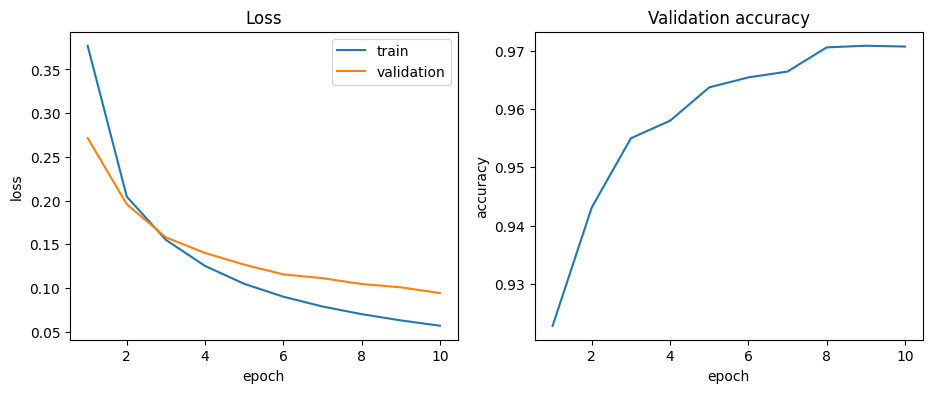

In [38]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(range(1, epochs+1), history["train_loss"], label="train")
ax1.plot(range(1, epochs+1), history["val_loss"], label="validation")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend(); ax1.set_title("Loss")
ax2.plot(range(1, epochs+1), history["val_acc"])
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.set_title("Validation accuracy")
plt.show()

**How can we tell that this is a good graph?**

Great question!

The reason **why**: `if both loss curves drop then it suggests the model is successfully learning and has adapted to its adjusted weights`
* if this WAS NOT the case (aka. training loss drops while the validation loss starts increasing), then that's **model overfitting.**

# **5. Gradient Checking**

Earlier we nuddged `w` and measured how the loss changed.

**The Checker**

In [39]:
def loss_now(X, y):
  return cross_entropy(forward(X), y)

def grad_check(param, analytic, X, y, n_checks=5, h=1e-5):
  rng = np.random.default_rng(1)
  candidates = np.flatnonzero(analytic)
  for i in rng.choice(candidates, n_checks, replace=False):
    old = param.flat[i]

    param.flat[i] = old + h
    loss_plus = loss_now(X, y)
    param.flat[i] = old - h
    loss_minus = loss_now(X, y)
    param.flat[i] = old

    numeric = (loss_plus - loss_minus) / (2*h)
    ana = analytic.flat[i]
    rel_err = abs(numeric - ana) / (abs(numeric) + abs(ana))
    print(f"analytic {ana: .8f} numeric {numeric: .8f} rel error {rel_err:.2e}")

In [40]:
Xg, yg = X_train[:20], y_train[:20]
Z1, A1, P = forward_full(Xg)
dW1, db1, dW2, db2 = backward(Xg, yg, Z1, A1, P)

for name, param, g in [("W1", W1, dW1), ("b1", b1, db1), ("W2", W2, dW2), ("b2", b2, db2)]:
  print(name)
  grad_check(param, g, Xg, yg)

W1
analytic  0.00670242 numeric  0.00670242 rel error 3.09e-11
analytic  0.00001110 numeric  0.00001110 rel error 2.69e-08
analytic -0.00584795 numeric -0.00584795 rel error 1.86e-11
analytic -0.00008785 numeric -0.00008785 rel error 6.50e-09
analytic -0.00008074 numeric -0.00008074 rel error 2.15e-09
b1
analytic  0.00021341 numeric  0.00021341 rel error 8.28e-10
analytic -0.00653672 numeric -0.00653672 rel error 6.38e-11
analytic  0.00102364 numeric  0.00102364 rel error 2.66e-10
analytic  0.00276780 numeric  0.00276780 rel error 5.26e-11
analytic -0.00689401 numeric -0.00689401 rel error 1.22e-10
W2
analytic  0.00000975 numeric  0.00000975 rel error 3.91e-08
analytic  0.00040578 numeric  0.00040578 rel error 9.02e-10
analytic  0.00011508 numeric  0.00011508 rel error 1.75e-09
analytic  0.02689617 numeric  0.02689617 rel error 5.80e-11
analytic -0.00063097 numeric -0.00063097 rel error 1.42e-10
b2
analytic  0.00924052 numeric  0.00924052 rel error 1.74e-11
analytic  0.00017801 numeric

**Triggering softmax overflow**

In [41]:
print(softmax(np.array([[1000.0, 1001.0, 999.0]])))

[[nan nan nan]]


/tmp/ipykernel_27994/1991567945.py:5: RuntimeWarning: overflow encountered in exp
  exp_z = np.exp(z)
/tmp/ipykernel_27994/1991567945.py:6: RuntimeWarning: invalid value encountered in divide
  return exp_z / exp_z.sum(axis=1, keepdims=True)


(the fix)

**Softmax overflow fix**

Original:
$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

Stable version, with $m = \max_j z_j$:
$$\text{softmax}(z)_i = \frac{e^{z_i - m}}{\sum_j e^{z_j - m}}$$

Why it's the same:
$$\frac{e^{z_i - m}}{\sum_j e^{z_j - m}} = \frac{e^{z_i}/e^{m}}{\sum_j e^{z_j}/e^{m}} = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

Why it can't overflow:
$$0 < e^{z_j - m} \le e^{0} = 1$$

**Softmax: turning scores into probabilities**

The network outputs 10 raw scores, one per digit. Softmax raises $e$ to the power of each score, which makes everything positive and exaggerates the gaps, then divides by the total so they sum to 1.

$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

The top is score $i$ after exponentiating; the bottom is all 10 exponentiated scores added together.

### Reaching For Higher Accuracy

In [42]:
# stable softmax
def softmax(z):
  z = z - z.max(axis=1, keepdims=True)
  exp_z = np.exp(z)
  return exp_z / exp_z.sum(axis=1, keepdims=True)

print(softmax(np.array([[1000.0, 1001.0, 999.0]])))

[[0.24472847 0.66524096 0.09003057]]




> Of course, another suitable option is to just train the model for longer or increase the learning rate to observe what happens. However, **gradient checking** is another option too. (something that PyTorch and Tensorflow do under the hood)



### **Final Test (test accuracy)**

In [43]:
y_test.shape

(7000,)

In [44]:
print("Test Accuracy", accuracy(X_test, y_test))

Test Accuracy 0.9732857142857143
